In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

# Use imblearn pipeline so SMOTE is only applied to the training folds during CV
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from hidden_risk.config import DATA_PROCESSED

# ---------------------------------------------------------
# 1. Load Data & Temporal Split
# ---------------------------------------------------------
print("Loading data and splitting temporally...")
df = pd.read_parquet(DATA_PROCESSED / "nhanes_2005_2018.parquet")

# Split based on the 'split' column created in Step 1
train_df = df[df['split'] == 'train'].copy()
test_df = df[df['split'] == 'test'].copy()

y_train = train_df['si'].astype(int)
y_test = test_df['si'].astype(int)

# Print outcome prevalence baseline
baseline_prev = y_test.mean()
print(f"Test Set Outcome Prevalence (Baseline PR-AUC): {baseline_prev:.3f} ({baseline_prev*100:.1f}%)")

# ---------------------------------------------------------
# 2. Define Nested Feature Sets
# ---------------------------------------------------------
# Demographics
features_demo = ['age', 'sex', 'ethnicity']

# Routine Health Data (Demographics + Meds + Morbidity + Social/Healthcare use)
features_routine = features_demo + [
    'education', 'marital_status', 'income_poverty_ratio', 'work_status', 'insured',
    'self_rated_health', 'hospital_stay', 'mental_health_visit', 'sleep_trouble',
    'asthma', 'arthritis', 'heart_failure', 'coronary_heart_disease', 'angina', 
    'heart_attack', 'stroke', 'emphysema', 'chronic_bronchitis', 'copd', 'cancer', 
    'diabetes', 'hypertension', 'high_cholesterol', 'bmi', 'rx_any', 'rx_count'
]

# PHQ-8 Only
features_phq8 = ['phq8_score']

# Routine + PHQ-8
features_routine_phq8 = features_routine + features_phq8

feature_sets = {
    "1. Demographics": features_demo,
    "2. Routine Health Data": features_routine,
    "3. PHQ-8 Only": features_phq8,
    "4. Routine + PHQ-8": features_routine_phq8
}

# ---------------------------------------------------------
# 3. Define Models & Imbalance Strategies
# ---------------------------------------------------------
def build_pipeline(model_type, imbalance_strategy):
    """Builds a flat imblearn pipeline with preprocessing, optional SMOTE, and the classifier."""
    
    # Flatten the steps so imbalanced-learn doesn't complain
    steps = [
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
    
    if imbalance_strategy == 'smote':
        steps.append(('smote', SMOTE(random_state=42)))
        
    # Select Model
    if model_type == 'lr':
        clf = LogisticRegression(
            max_iter=1000, 
            class_weight='balanced' if imbalance_strategy == 'weighted' else None,
            random_state=42
        )
    elif model_type == 'hgb':
        # HistGradientBoosting handles imbalance natively if sample weights are passed, 
        # but for this pipeline setup we will rely on SMOTE for its imbalance test.
        clf = HistGradientBoostingClassifier(random_state=42)
    
    steps.append(('classifier', clf))
    
    return ImbPipeline(steps)

# ---------------------------------------------------------
# 4. Training and Evaluation Loop
# ---------------------------------------------------------
models = ['lr', 'hgb']
strategies = ['none', 'weighted', 'smote']

results = []

print("\nStarting Model Training and Evaluation...\n")

for set_name, cols in feature_sets.items():
    print(f"--- Evaluating Feature Set: {set_name} ---")
    X_train = train_df[cols]
    X_test = test_df[cols]
    
    for mod in models:
        for strat in strategies:
            # Skip weighting for HGB as it doesn't support class_weight natively in the exact same way as LR
            if mod == 'hgb' and strat == 'weighted':
                continue 
                
            pipeline = build_pipeline(mod, strat)
            
            # Train the model
            pipeline.fit(X_train, y_train)
            
            # Predict probabilities on the 2015-2018 Test Set
            y_pred_proba = pipeline.predict_proba(X_test)[:, 1]
            
            # Calculate Metrics
            pr_auc = average_precision_score(y_test, y_pred_proba)
            roc_auc = roc_auc_score(y_test, y_pred_proba)
            
            results.append({
                "Feature Set": set_name,
                "Model": "LogReg" if mod == 'lr' else "HistGradBoost",
                "Imbalance Strat": strat.upper(),
                "PR-AUC": round(pr_auc, 3),
                "ROC-AUC": round(roc_auc, 3)
            })

# ---------------------------------------------------------
# 5. Display Results
# ---------------------------------------------------------
results_df = pd.DataFrame(results)

print("\n=== STEP 4 MODELLING RESULTS ===")
print(results_df.to_string(index=False))

Loading data and splitting temporally...
Test Set Outcome Prevalence (Baseline PR-AUC): 0.038 (3.8%)

Starting Model Training and Evaluation...

--- Evaluating Feature Set: 1. Demographics ---


c:\users\dimpr\appdata\local\programs\python\python39\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
c:\users\dimpr\appdata\local\programs\python\python39\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


--- Evaluating Feature Set: 2. Routine Health Data ---


c:\users\dimpr\appdata\local\programs\python\python39\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
c:\users\dimpr\appdata\local\programs\python\python39\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


--- Evaluating Feature Set: 3. PHQ-8 Only ---


c:\users\dimpr\appdata\local\programs\python\python39\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
c:\users\dimpr\appdata\local\programs\python\python39\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


--- Evaluating Feature Set: 4. Routine + PHQ-8 ---


c:\users\dimpr\appdata\local\programs\python\python39\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
c:\users\dimpr\appdata\local\programs\python\python39\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(



=== STEP 4 MODELLING RESULTS ===
           Feature Set         Model Imbalance Strat  PR-AUC  ROC-AUC
       1. Demographics        LogReg            NONE   0.043    0.520
       1. Demographics        LogReg        WEIGHTED   0.043    0.520
       1. Demographics        LogReg           SMOTE   0.043    0.520
       1. Demographics HistGradBoost            NONE   0.042    0.521
       1. Demographics HistGradBoost           SMOTE   0.041    0.519
2. Routine Health Data        LogReg            NONE   0.130    0.770
2. Routine Health Data        LogReg        WEIGHTED   0.129    0.771
2. Routine Health Data        LogReg           SMOTE   0.127    0.766
2. Routine Health Data HistGradBoost            NONE   0.112    0.753
2. Routine Health Data HistGradBoost           SMOTE   0.108    0.742
         3. PHQ-8 Only        LogReg            NONE   0.315    0.901
         3. PHQ-8 Only        LogReg        WEIGHTED   0.315    0.901
         3. PHQ-8 Only        LogReg           SMOTE   0

=== CALIBRATION & METRICS ===
Brier Score: 0.0345


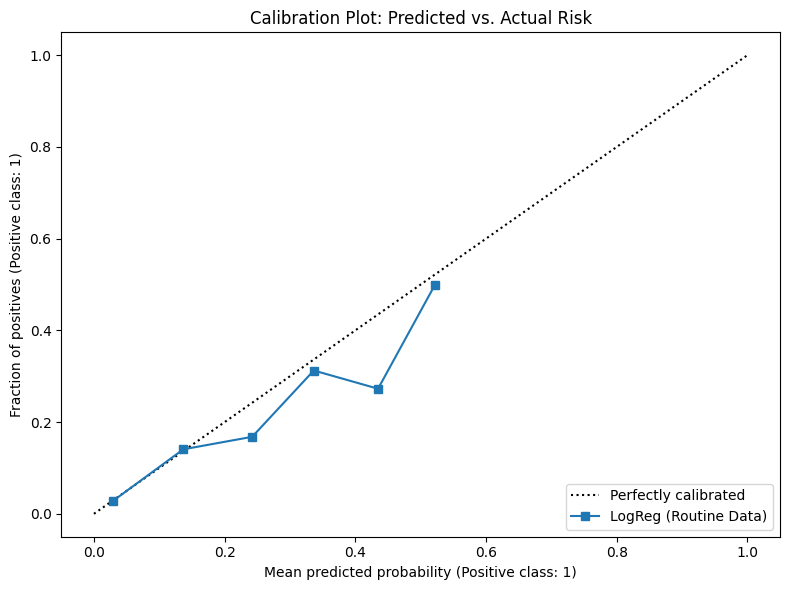


=== CLINICAL OPERATING POINT ===
Threshold for Top 5%: 0.1293
Flagging 1 in 20 patients catches 23.0% of cases, of whom 17.2% are true positives.

=== FAIRNESS ANALYSIS (H4) ===
Demographic Subgroup Prevalence  ROC-AUC PR-AUC (vs Prev) Recall @ Top 5%
  age_group (18, 29]       3.9%    0.746     0.131 (x3.4)           20.3%
  age_group (29, 44]       3.3%    0.774     0.151 (x4.6)           27.6%
  age_group (44, 59]       3.9%    0.773     0.129 (x3.3)           25.0%
  age_group (59, 80]       3.9%    0.772     0.139 (x3.6)           20.7%
  ethnicity        1       4.1%    0.778     0.159 (x3.9)           28.4%
  ethnicity        2       5.2%    0.792     0.167 (x3.2)           29.3%
  ethnicity        3       3.8%    0.779     0.146 (x3.8)           22.4%
  ethnicity        4       2.7%    0.782     0.103 (x3.8)           21.0%
  ethnicity        5       3.7%    0.752     0.130 (x3.5)           14.5%
        sex        1       4.0%    0.766     0.160 (x4.0)           20.2%
       

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, precision_score, recall_score
from sklearn.calibration import CalibrationDisplay

# ---------------------------------------------------------
# 1. Retrain the Best Realistic Model
# ---------------------------------------------------------
# We use Logistic Regression on Routine Health Data (No Imbalance Correction) 
# as it showed strong PR-AUC without artificial distortion.
X_train_best = train_df[features_routine]
X_test_best = test_df[features_routine]

best_pipeline = build_pipeline('lr', 'none')
best_pipeline.fit(X_train_best, y_train)

y_pred_proba = best_pipeline.predict_proba(X_test_best)[:, 1]

# ---------------------------------------------------------
# 2. Calibration & Secondary Metrics
# ---------------------------------------------------------
brier = brier_score_loss(y_test, y_pred_proba)
print("=== CALIBRATION & METRICS ===")
print(f"Brier Score: {brier:.4f}")

# Plot Calibration Curve
fig, ax = plt.subplots(figsize=(8, 6))
CalibrationDisplay.from_predictions(y_test, y_pred_proba, n_bins=10, ax=ax, name="LogReg (Routine Data)")
plt.title("Calibration Plot: Predicted vs. Actual Risk")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 3. Clinical Operating Point (Top 5% of Patients)
# ---------------------------------------------------------
# Find the probability threshold that flags exactly the top 5% of the test set
top_5_threshold = np.percentile(y_pred_proba, 95)

# Create binary flags: 1 if >= threshold, 0 otherwise
y_pred_top5 = (y_pred_proba >= top_5_threshold).astype(int)

# Calculate precision and recall at this threshold
recall_top5 = recall_score(y_test, y_pred_top5)
precision_top5 = precision_score(y_test, y_pred_top5)

print("\n=== CLINICAL OPERATING POINT ===")
print(f"Threshold for Top 5%: {top_5_threshold:.4f}")
print(f"Flagging 1 in 20 patients catches {recall_top5*100:.1f}% of cases, of whom {precision_top5*100:.1f}% are true positives.")

# ---------------------------------------------------------
# 4. Fairness Analysis (H4)
# ---------------------------------------------------------
print("\n=== FAIRNESS ANALYSIS (H4) ===")
# Create age groups in test set for the analysis
test_df['age_group'] = pd.cut(test_df['age'], bins=[18, 29, 44, 59, 80], right=True)

fairness_results = []
demographics = ['sex', 'age_group', 'ethnicity']

for demo in demographics:
    # Drop NaNs to ensure clean group metrics
    valid_idx = test_df[demo].dropna().index
    
    for group in test_df.loc[valid_idx, demo].unique():
        # Get indices for the specific subgroup
        group_idx = test_df[test_df[demo] == group].index
        
        y_test_group = y_test.loc[group_idx]
        y_pred_proba_group = y_pred_proba[test_df.index.get_indexer(group_idx)]
        y_pred_top5_group = y_pred_top5[test_df.index.get_indexer(group_idx)]
        
        # Only calculate if there are actual cases in this subgroup to avoid division by zero
        if y_test_group.sum() > 0:
            group_prev = y_test_group.mean()
            group_roc = roc_auc_score(y_test_group, y_pred_proba_group)
            group_pr = average_precision_score(y_test_group, y_pred_proba_group)
            group_recall = recall_score(y_test_group, y_pred_top5_group)
            
            fairness_results.append({
                "Demographic": demo,
                "Subgroup": str(group),  # Converted to string to fix the sorting error
                "Prevalence": f"{group_prev*100:.1f}%",
                "ROC-AUC": round(group_roc, 3),
                "PR-AUC (vs Prev)": f"{group_pr:.3f} (x{group_pr/group_prev:.1f})",
                "Recall @ Top 5%": f"{group_recall*100:.1f}%"
            })

fairness_df = pd.DataFrame(fairness_results).sort_values(by=["Demographic", "Subgroup"])
print(fairness_df.to_string(index=False))

c:\users\dimpr\appdata\local\programs\python\python39\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


=== LOGISTIC REGRESSION ODDS RATIOS (TOP 10) ===
               Feature  Odds Ratio (per 1 SD increase)
     self_rated_health                        1.569943
         sleep_trouble                        1.279215
   mental_health_visit                        1.270238
           work_status                        1.199757
        marital_status                        1.174681
                stroke                        1.076677
                   sex                        1.067332
              rx_count                        1.059212
coronary_heart_disease                        1.043139
      high_cholesterol                        1.036520

=== SHAP EXPLAINABILITY (GRADIENT BOOSTING) ===


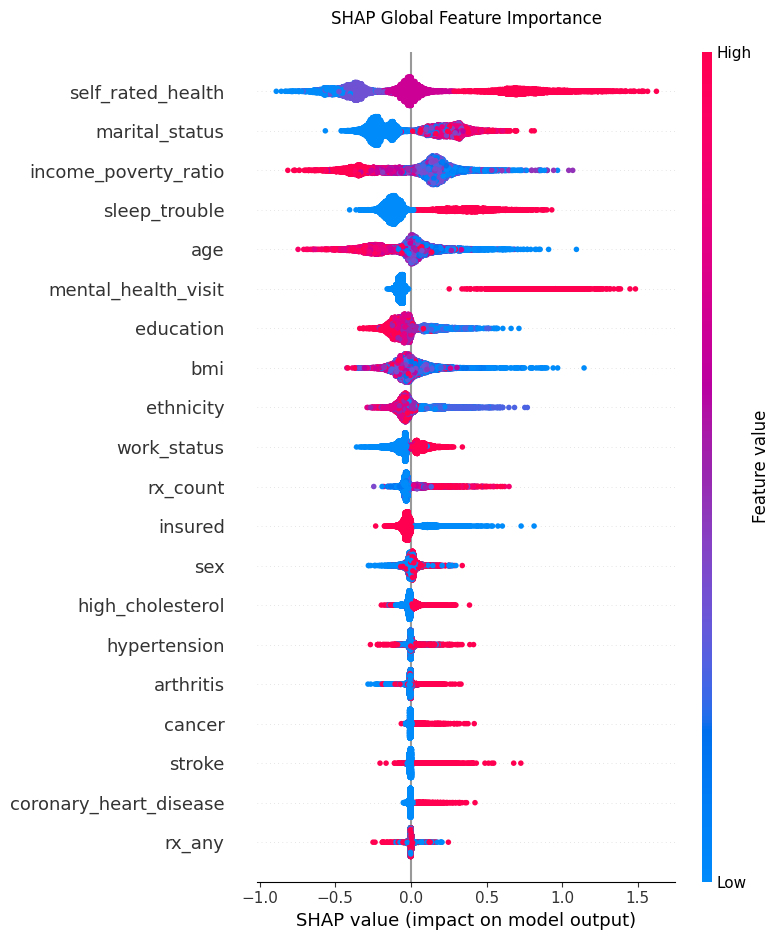


--- Patient #6711 Explanation ---
Predicted Probability of Suicidal Ideation: 73.0%


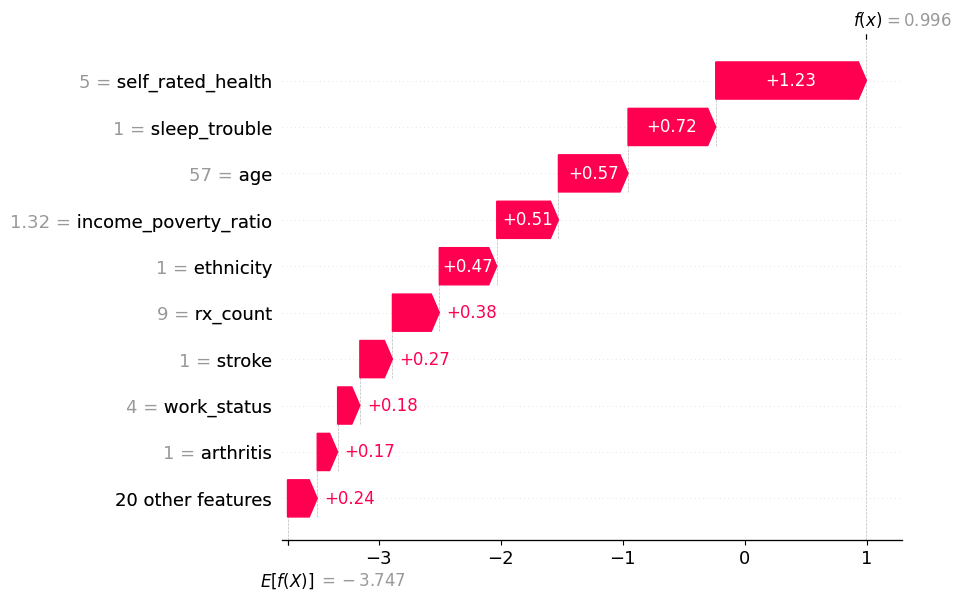


--- Patient #3694 Explanation ---
Predicted Probability of Suicidal Ideation: 75.0%


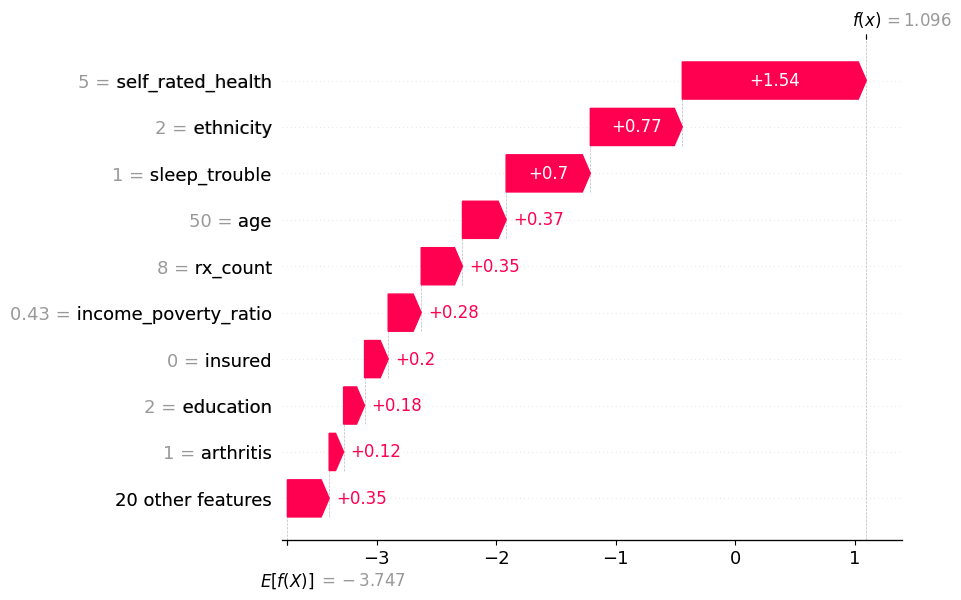

In [12]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline

# ---------------------------------------------------------
# 1. Logistic Regression: Odds Ratios
# ---------------------------------------------------------
print("=== LOGISTIC REGRESSION ODDS RATIOS (TOP 10) ===")
# Extract the trained Logistic Regression model from our best_pipeline
lr_model = best_pipeline.named_steps['classifier']

# Exponentiate the coefficients to get Standardized Odds Ratios
# (Standardized because we passed the data through StandardScaler)
odds_ratios = np.exp(lr_model.coef_[0])

or_df = pd.DataFrame({
    'Feature': features_routine,
    'Odds Ratio (per 1 SD increase)': odds_ratios
}).sort_values(by='Odds Ratio (per 1 SD increase)', ascending=False)

print(or_df.head(10).to_string(index=False))

# ---------------------------------------------------------
# 2. Gradient Boosting: SHAP Values
# ---------------------------------------------------------
print("\n=== SHAP EXPLAINABILITY (GRADIENT BOOSTING) ===")

# Rebuild and fit HGB *without* StandardScaler (tree models don't need scaling).
# This makes SHAP values much easier to interpret on their original clinical scale!
hgb_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', HistGradientBoostingClassifier(random_state=42))
])
hgb_pipeline.fit(X_train_best, y_train)

# Pass test data through the imputer so SHAP can read it
X_test_imputed = pd.DataFrame(
    hgb_pipeline.named_steps['imputer'].transform(X_test_best),
    columns=features_routine
)

# Generate SHAP values
explainer = shap.Explainer(hgb_pipeline.named_steps['classifier'])
shap_values = explainer(X_test_imputed)

# Global Feature Importance Plot
plt.figure()
plt.title("SHAP Global Feature Importance", pad=20)
shap.summary_plot(shap_values, X_test_imputed, show=False)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 3. Individual Patient Explanations (2 High-Risk Cases)
# ---------------------------------------------------------
y_pred_proba_hgb = hgb_pipeline.predict_proba(X_test_best)[:, 1]

# Find the indices of the 2 patients with the highest predicted risk
high_risk_indices = np.argsort(y_pred_proba_hgb)[-2:] 

for idx in high_risk_indices:
    print(f"\n--- Patient #{idx} Explanation ---")
    print(f"Predicted Probability of Suicidal Ideation: {y_pred_proba_hgb[idx]*100:.1f}%")
    # Generate a waterfall plot to explain exactly WHY this specific patient was flagged
    shap.plots.waterfall(shap_values[idx])